In [2]:
import rasterio
import numpy
import matplotlib.pyplot as plt
import torch
import segmentation_models_pytorch as smp
import torch.nn.functional as F

c:\Users\kai\miniconda3\envs\sds-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
image_id_list = [
    "Mekong_1111068",
    "Mekong_1149855",
    "Mekong_1191208",
    "Mekong_119477",
    "Mekong_1248200",
    "Mekong_1282475",
    "Mekong_1395593",
    "Mekong_1396181",
    "Mekong_1413877",
    "Mekong_1439641",
    "Mekong_1443339",
    "Mekong_16233",
    "Mekong_213094",
    "Mekong_221789",
    "Mekong_254910",
    "Mekong_269835",
    "Mekong_333434",
    "Mekong_342411",
    "Mekong_382276",
    "Mekong_424793",
    "Mekong_474783",
    "Mekong_52610",
    "Mekong_596495",
    "Mekong_774566",
    "Mekong_846007",
    "Mekong_922373",
    "Sri-Lanka_101973",
    "Sri-Lanka_1038087",
    "Sri-Lanka_117737",
    "Sri-Lanka_120804",
    "Sri-Lanka_132922",
    "Sri-Lanka_135713",
    "Sri-Lanka_14484",
    "Sri-Lanka_152185",
    "Sri-Lanka_163406",
    "Sri-Lanka_178753",
    "Sri-Lanka_233609",
    "Sri-Lanka_236030",
    "Sri-Lanka_236628",
    "Sri-Lanka_249079",
    "Sri-Lanka_31559",
    "Sri-Lanka_321316",
    "Sri-Lanka_377277",
    "Sri-Lanka_400518",
    "Sri-Lanka_450918",
    "Sri-Lanka_49764",
    "Sri-Lanka_52223",
    "Sri-Lanka_523539",
    "Sri-Lanka_534068",
    "Sri-Lanka_551926",
    "Sri-Lanka_55568",
    "Sri-Lanka_579082",
    "Sri-Lanka_612594",
    "Sri-Lanka_63307",
    "Sri-Lanka_649970",
    "Sri-Lanka_653336",
    "Sri-Lanka_713926",
    "Sri-Lanka_748447",
    "Sri-Lanka_845821",
    "Sri-Lanka_847275",
    "Sri-Lanka_849649",
    "Sri-Lanka_85652",
    "Sri-Lanka_883641",
    "Sri-Lanka_922192",
]

somali_image_ids = [
    "Somalia_7931",
    "Somalia_12849",
    "Somalia_32375",
    "Somalia_60129",
    "Somalia_61368",
    "Somalia_93023",
    "Somalia_94102",
    "Somalia_166342",
    "Somalia_167787",
    "Somalia_195014",
    "Somalia_205466",
    "Somalia_230192",
    "Somalia_256539",
    "Somalia_295782",
    "Somalia_322855",
    "Somalia_371421",
    "Somalia_626316",
    "Somalia_649376",
    "Somalia_685158",
    "Somalia_699062",
    "Somalia_886726",
    "Somalia_970508",
    "Somalia_989553",
    "Somalia_992457",
    "Somalia_1068756",
    "Somalia_1087508",
]


In [4]:
#Load paths/images with their corresponding image_id's
def load_image(image_id):

    s1_path = f"data/S1Hand/{image_id}_S1Hand.tif"
    label_path = f"data/LabelHand/{image_id}_LabelHand.tif"

    with rasterio.open(s1_path) as src:
        vv = src.read(1)
        vh = src.read(2)

    with rasterio.open(label_path) as src:
        label = src.read(1)

    return vv, vh, label


# Normalization of the raw SAR values (radiation) by using the z-score normalization function
# Function receives the channel with the SAR values and "valid_mask", meaning that pixels are checked if they are valid (not infinite etc.)
def normalize_channel(channel, valid_mask):
    values = channel[valid_mask]

    mean = numpy.mean(values)
    std = numpy.std(values)

    normalized = (channel - mean) / max(std, 0.000001)

    # Find NaN and infinity values, then set them to 0
    normalized[~valid_mask] = 0

    return normalized.astype(numpy.float32)

# Prepare image for U-Net
def prepare_image(vv, vh, label):
    # Define the Pixels where both SAR channels and the label are valid (value not infinite and not label -1)
    valid_mask = (
        numpy.isfinite(vv)
        & numpy.isfinite(vh)
        & numpy.isin(label, [0, 1]))

# Normalize both channels
    vv_normalized = normalize_channel(vv, valid_mask)
    vh_normalized = normalize_channel(vh, valid_mask)

    # Combine both images 
    input_image = numpy.stack([vv_normalized, vh_normalized], axis=0)

    # Water mask
    water_pixel = (label == 1).astype(numpy.float32)

    return input_image, water_pixel, valid_mask

In [5]:
images = []
targets = []
valid_masks = []

test_image_ids = somali_image_ids

for image_id in image_id_list:
    vv, vh, label = load_image(image_id)

    input_image, water_pixel, valid_mask = prepare_image(vv, vh, label)
    
    # Save output into lists
    images.append(input_image)
    targets.append(water_pixel)
    valid_masks.append(valid_mask)

In [6]:
# Prepare data for PyTorch with tensor and adding another dimension with unsqueeze
# Convert all five images and masks into PyTorch tensors
image_tensor = torch.from_numpy(numpy.stack(images))

target_tensor = torch.from_numpy(numpy.stack(targets)).unsqueeze(1)

valid_tensor = torch.from_numpy(numpy.stack(valid_masks).astype(numpy.float32)).unsqueeze(1)

# Create U-net
model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=2,
    classes=1)

# Use optimizer to adjust weights in U-net
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
#training
epochs = 95
batch_size = 4

train_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for start in range(0, len(image_tensor), batch_size):
        x = image_tensor[start:start + batch_size]
        y = target_tensor[start:start + batch_size]
        valid = valid_tensor[start:start + batch_size]

        optimizer.zero_grad()

        prediction = model(x)

        pixel_loss = F.binary_cross_entropy_with_logits(
            prediction, y, reduction="none"
        )

        loss = (pixel_loss * valid).sum() / valid.sum().clamp_min(1)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / (
        (len(image_tensor) + batch_size - 1) // batch_size
    )

    train_losses.append(average_loss)

    print(f"Epoch {epoch+1}/{epochs} - Loss: {average_loss:.4f}")

Epoch 1/95 - Loss: 0.5471
Epoch 2/95 - Loss: 0.4657
Epoch 3/95 - Loss: 0.3968
Epoch 4/95 - Loss: 0.3712
Epoch 5/95 - Loss: 0.3489
Epoch 6/95 - Loss: 0.3415
Epoch 7/95 - Loss: 0.3290
Epoch 8/95 - Loss: 0.3206
Epoch 9/95 - Loss: 0.3148
Epoch 10/95 - Loss: 0.3121
Epoch 11/95 - Loss: 0.2943
Epoch 12/95 - Loss: 0.2955
Epoch 13/95 - Loss: 0.3030
Epoch 14/95 - Loss: 0.2875
Epoch 15/95 - Loss: 0.2889
Epoch 16/95 - Loss: 0.2874
Epoch 17/95 - Loss: 0.2570
Epoch 18/95 - Loss: 0.2511
Epoch 19/95 - Loss: 0.2476
Epoch 20/95 - Loss: 0.2559
Epoch 21/95 - Loss: 0.2357
Epoch 22/95 - Loss: 0.2250
Epoch 23/95 - Loss: 0.2464
Epoch 24/95 - Loss: 0.2596
Epoch 25/95 - Loss: 0.2549
Epoch 26/95 - Loss: 0.2451
Epoch 27/95 - Loss: 0.2257
Epoch 28/95 - Loss: 0.1918
Epoch 29/95 - Loss: 0.1784
Epoch 30/95 - Loss: 0.1906
Epoch 31/95 - Loss: 0.1580
Epoch 32/95 - Loss: 0.1506
Epoch 33/95 - Loss: 0.1565
Epoch 34/95 - Loss: 0.1661
Epoch 35/95 - Loss: 0.1634
Epoch 36/95 - Loss: 0.1370
Epoch 37/95 - Loss: 0.1480
Epoch 38/9

In [8]:
import torch
import segmentation_models_pytorch as smp

model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=2,
    classes=1
)

model.load_state_dict(
    torch.load("unet_95epochs.pth", map_location="cpu", weights_only=True)
)

model.eval()

print("Trained model loaded successfully!")

Trained model loaded successfully!


In [15]:
model.eval()

test_results = []
total_intersection = 0
total_union = 0

for image_id in test_image_ids:

    vv, vh, label = load_image(image_id)
    test_image, test_target, test_valid = prepare_image(vv, vh, label)

    test_tensor = torch.from_numpy(test_image).unsqueeze(0)

    with torch.no_grad():
        prediction = model(test_tensor)

    prob_map = torch.sigmoid(prediction)[0, 0].numpy()
    pred_mask = prob_map >= 0.09
    ground_truth = test_target == 1

    intersection = numpy.sum(
        ground_truth & pred_mask & test_valid
    )

    union = numpy.sum(
        (ground_truth | pred_mask) & test_valid
    )

    water_iou = intersection / union if union > 0 else numpy.nan

    test_results.append((image_id, water_iou))
    total_intersection += intersection
    total_union += union

    print(f"{image_id}: Water IoU = {water_iou:.4f}")

print()
print("Mean Water IoU:", round(
    numpy.nanmean([iou for _, iou in test_results]), 4
))

print("Overall Water IoU:", round(
    total_intersection / total_union, 4
) if total_union > 0 else "Undefined")

Somalia_7931: Water IoU = 0.0000
Somalia_12849: Water IoU = 0.1782
Somalia_32375: Water IoU = 0.0000
Somalia_60129: Water IoU = 0.0103
Somalia_61368: Water IoU = 0.0000
Somalia_93023: Water IoU = 0.0000
Somalia_94102: Water IoU = 0.4980
Somalia_166342: Water IoU = 0.0000
Somalia_167787: Water IoU = 0.0103
Somalia_195014: Water IoU = 0.0000
Somalia_205466: Water IoU = 0.0009
Somalia_230192: Water IoU = 0.0033
Somalia_256539: Water IoU = 0.0001
Somalia_295782: Water IoU = 0.1728
Somalia_322855: Water IoU = 0.6595
Somalia_371421: Water IoU = 0.1701
Somalia_626316: Water IoU = 0.2417
Somalia_649376: Water IoU = 0.0411
Somalia_685158: Water IoU = 0.4664
Somalia_699062: Water IoU = 0.1147
Somalia_886726: Water IoU = 0.4382
Somalia_970508: Water IoU = 0.2431
Somalia_989553: Water IoU = 0.0000
Somalia_992457: Water IoU = 0.0847
Somalia_1068756: Water IoU = 0.0392
Somalia_1087508: Water IoU = 0.1579

Mean Water IoU: 0.1358
Overall Water IoU: 0.1815


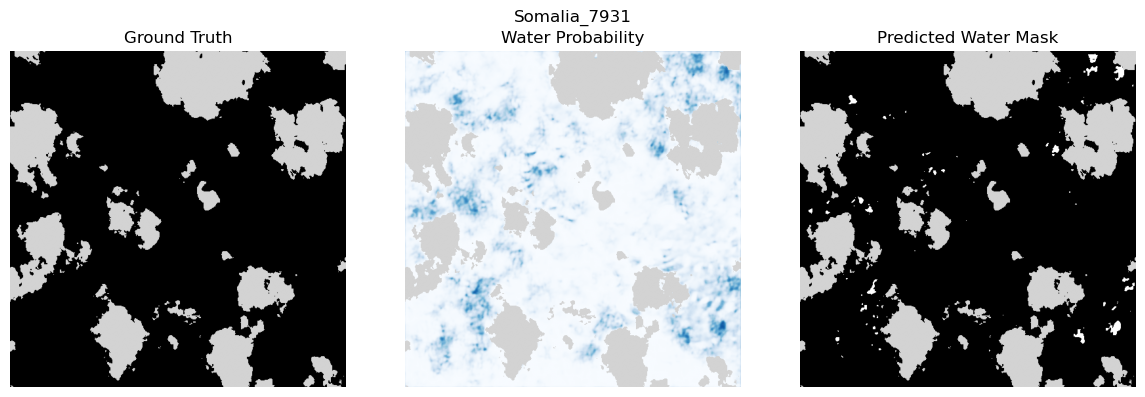

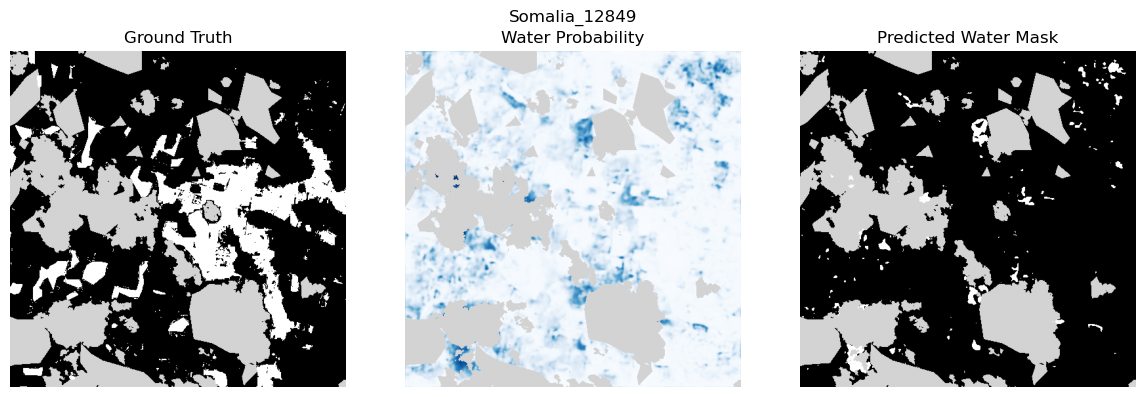

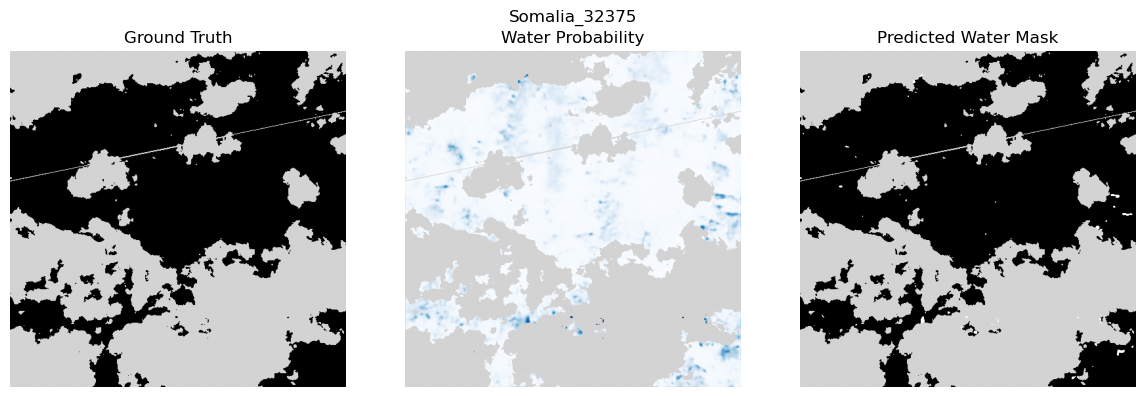

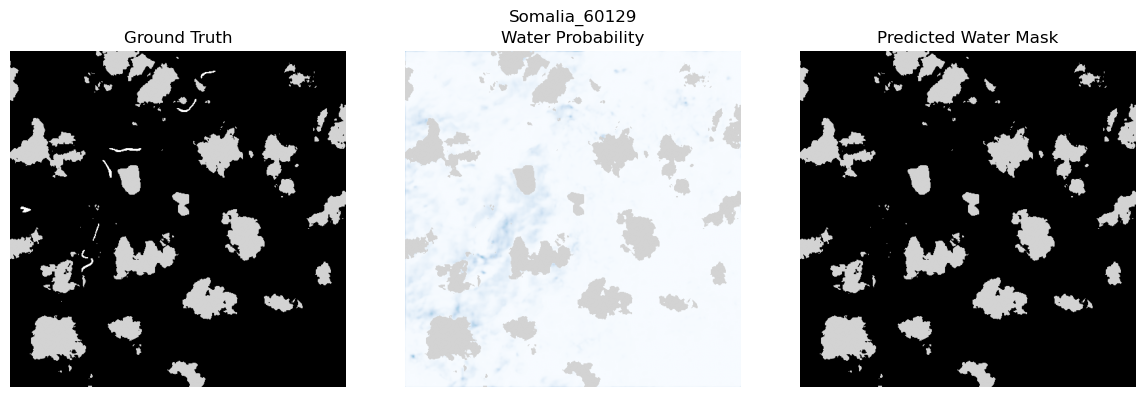

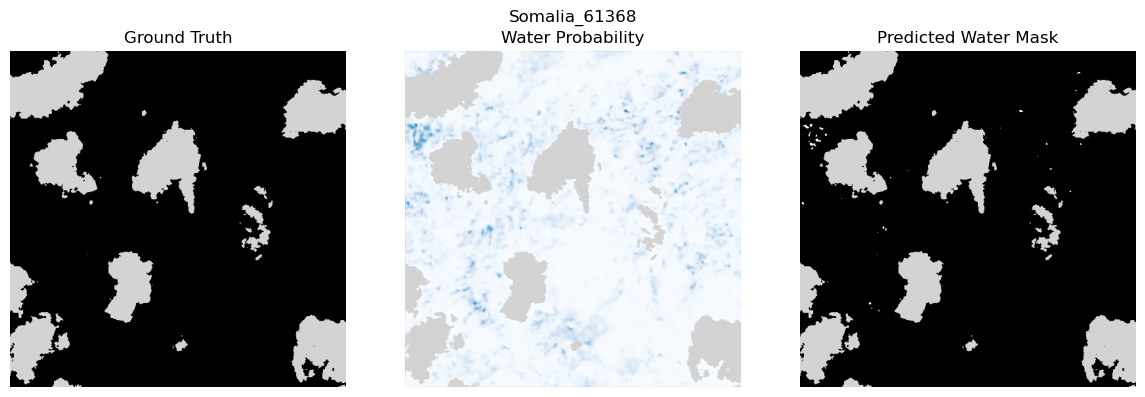

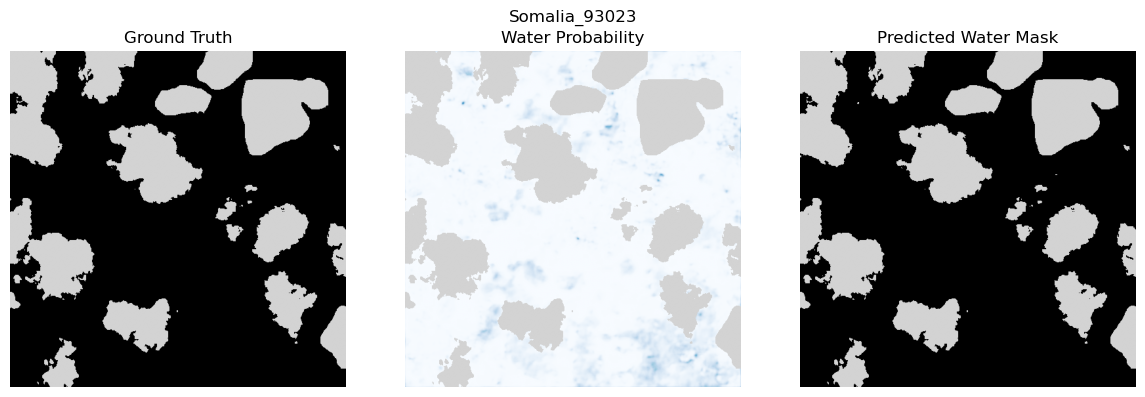

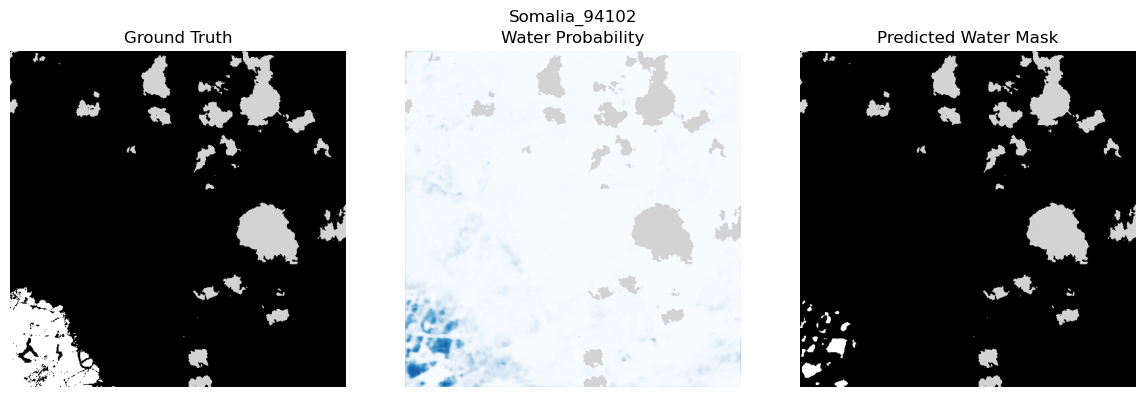

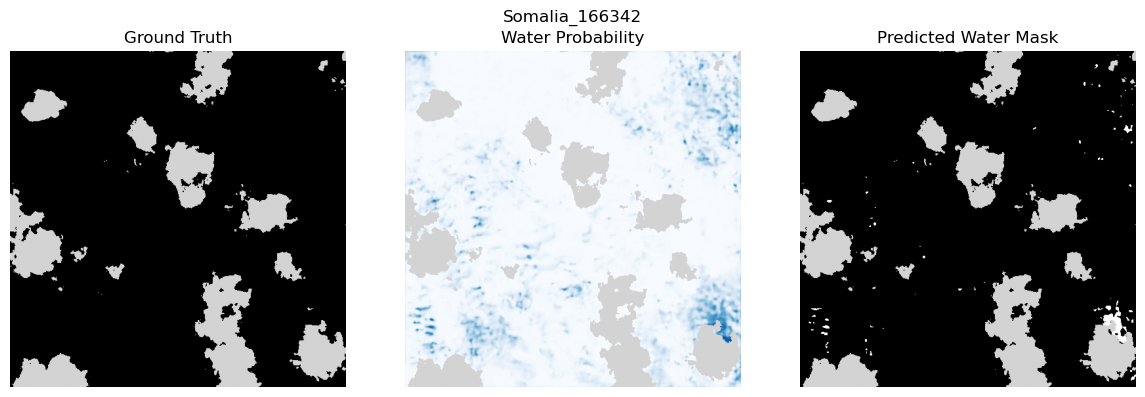

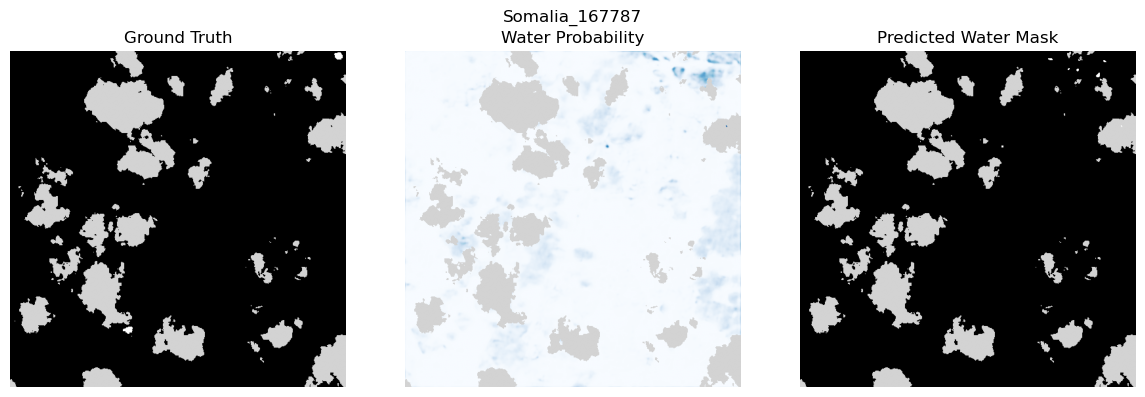

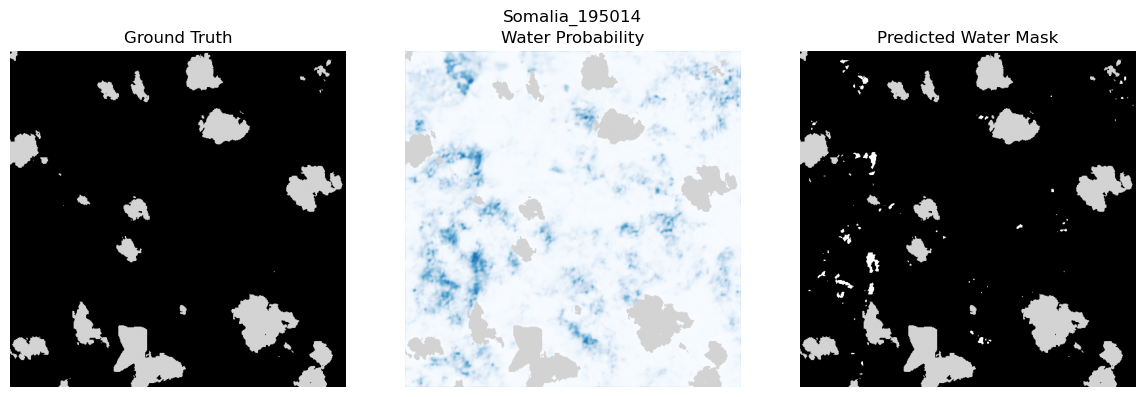

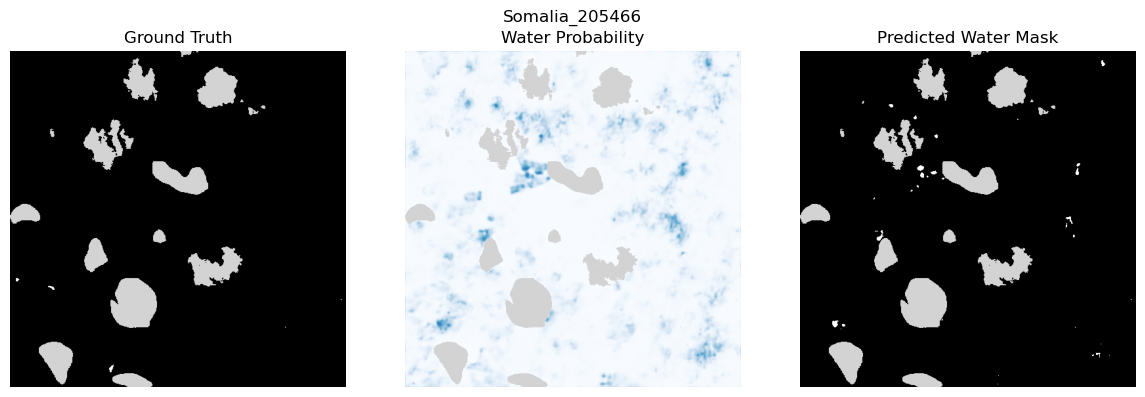

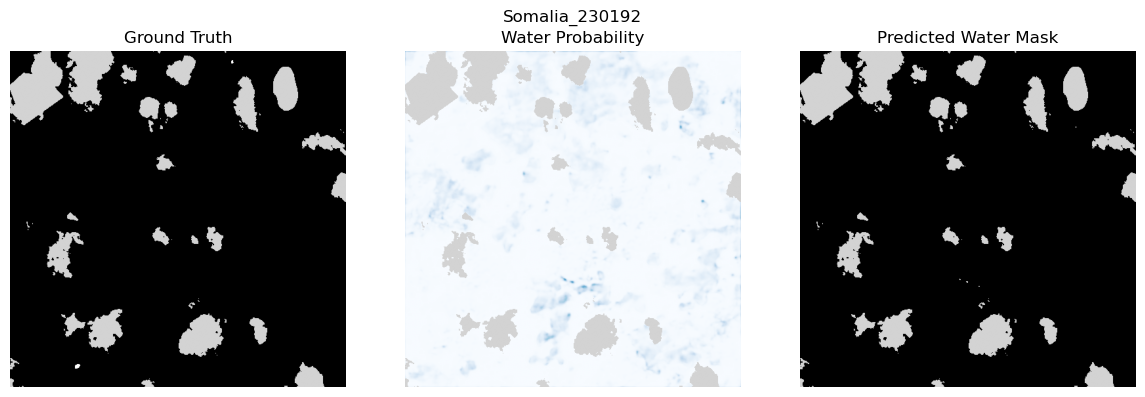

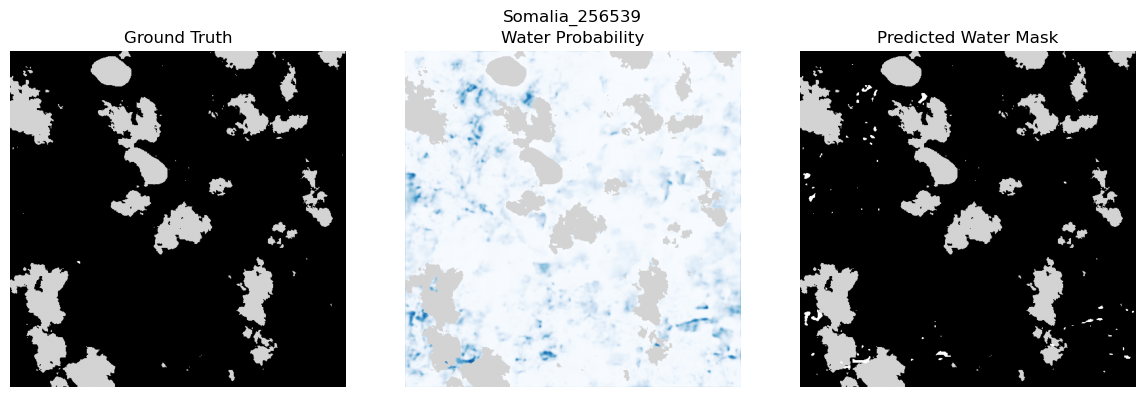

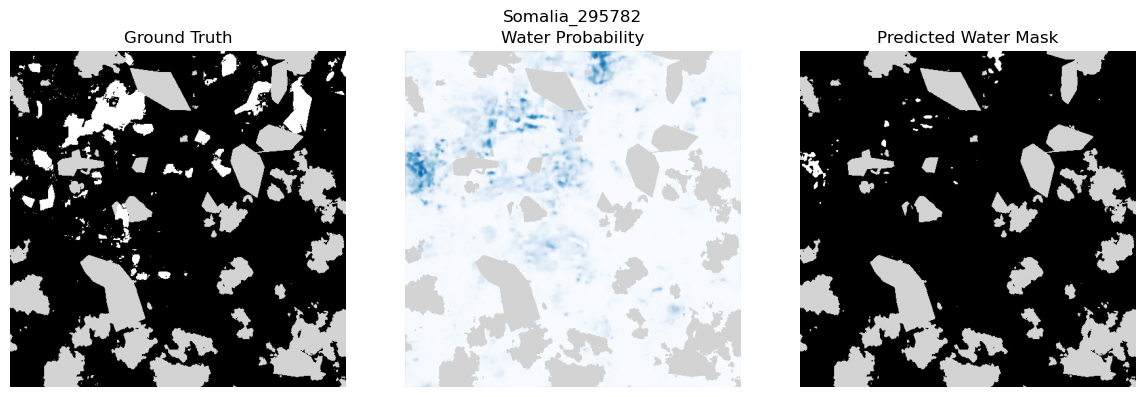

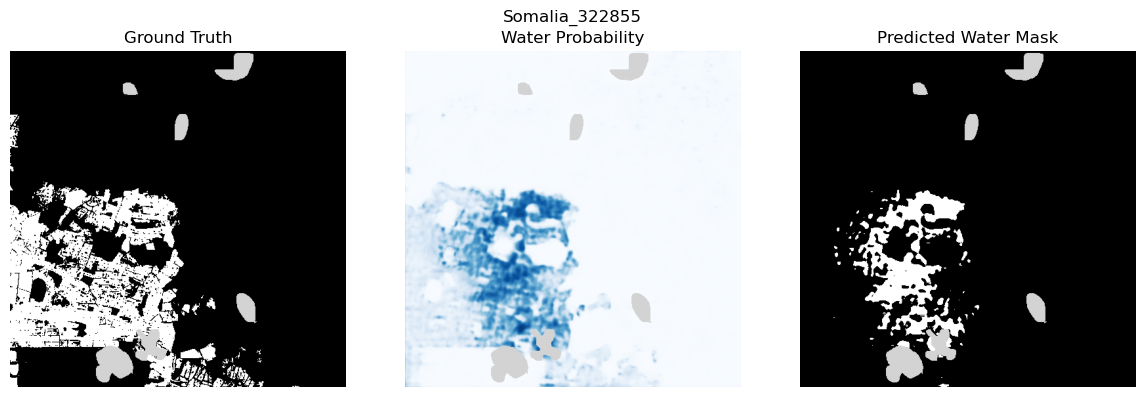

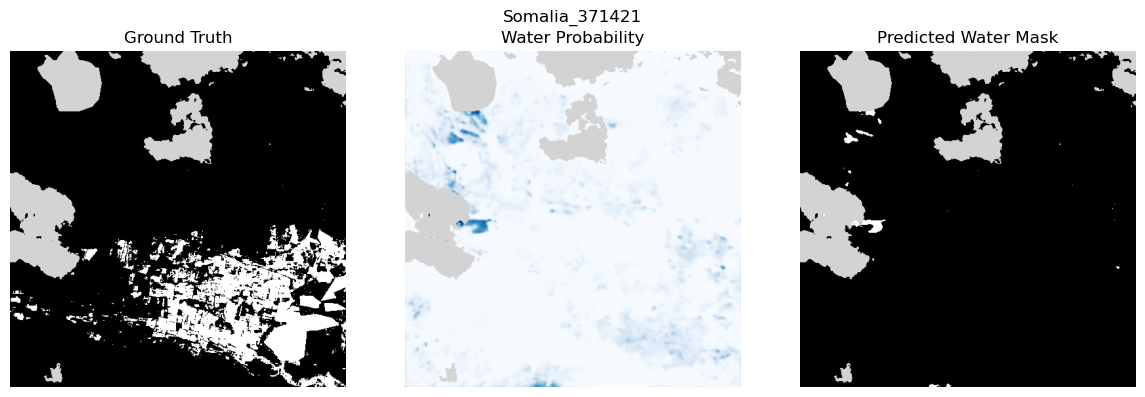

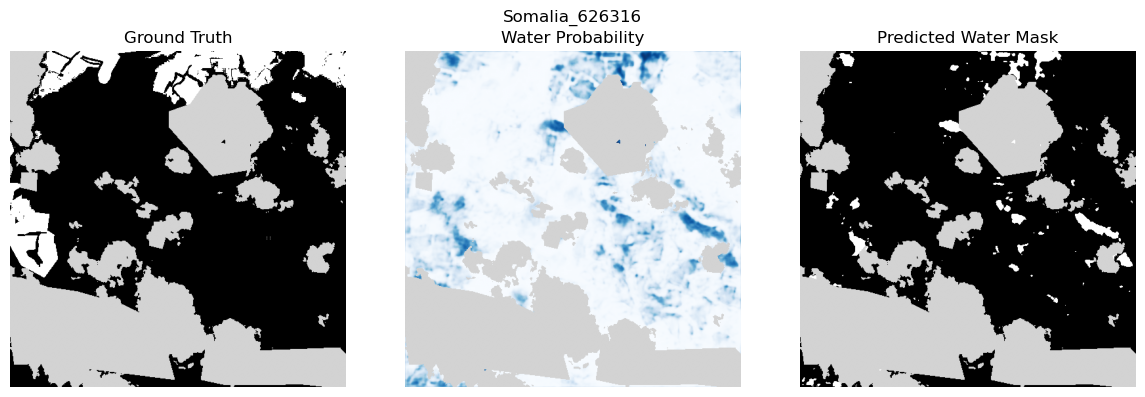

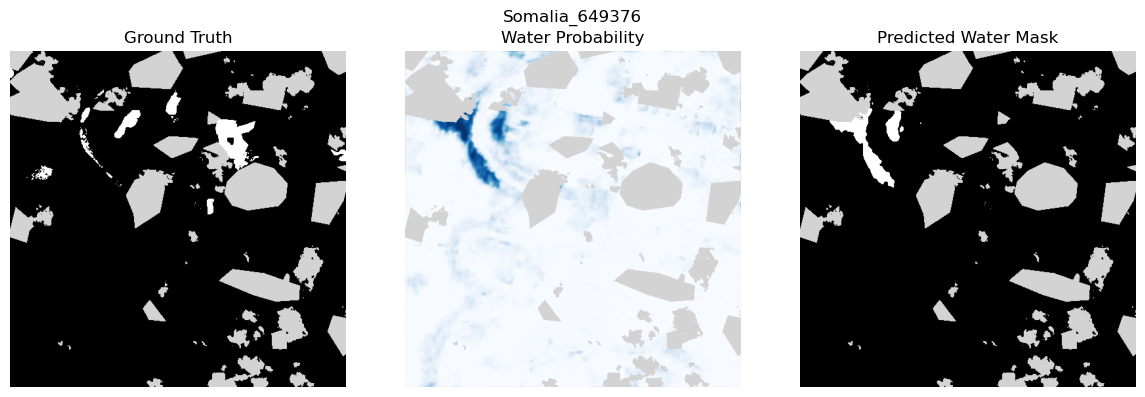

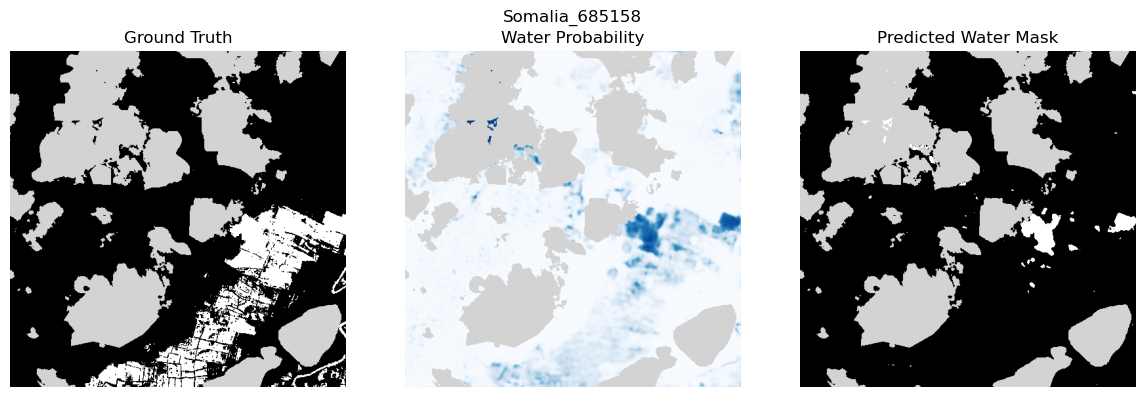

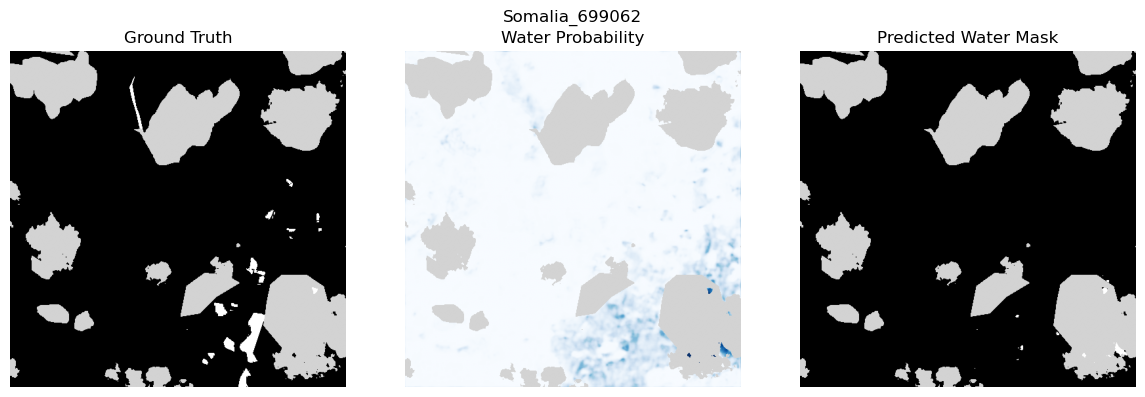

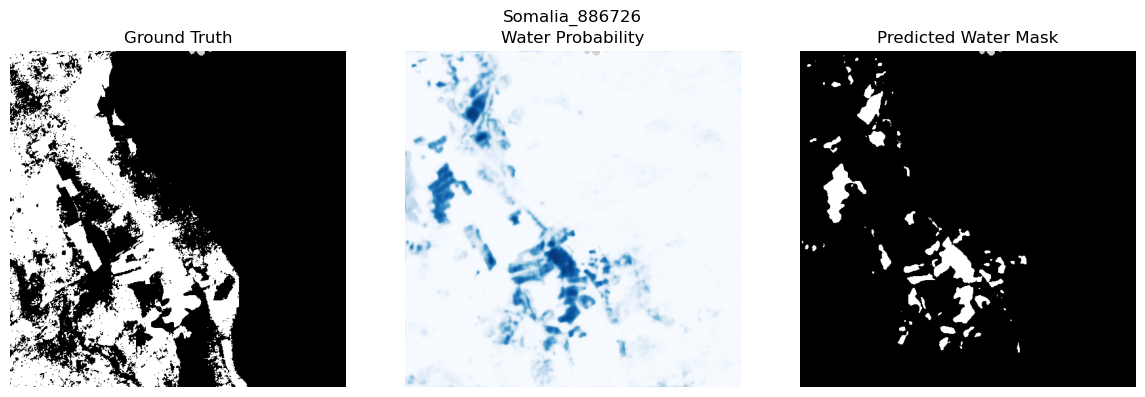

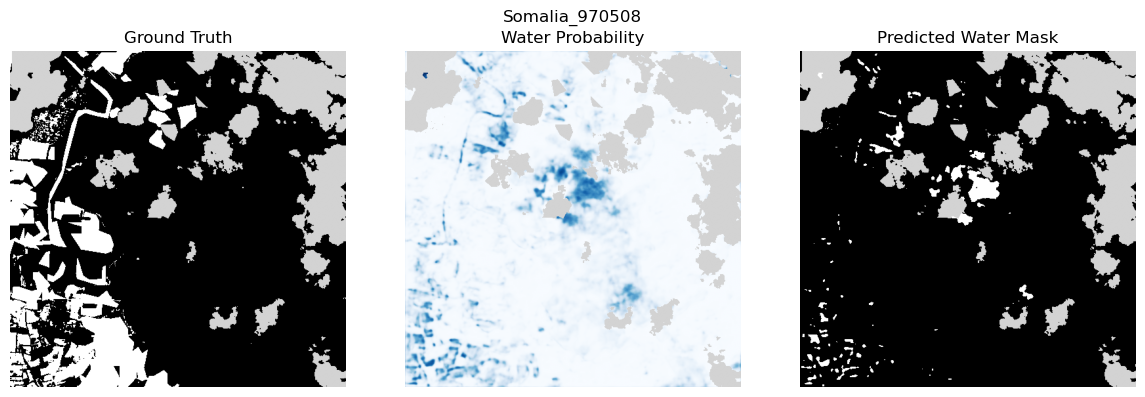

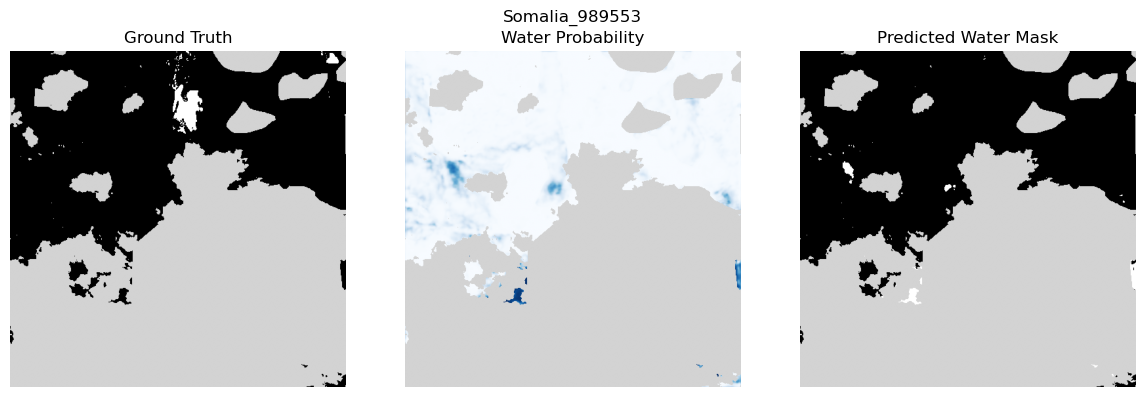

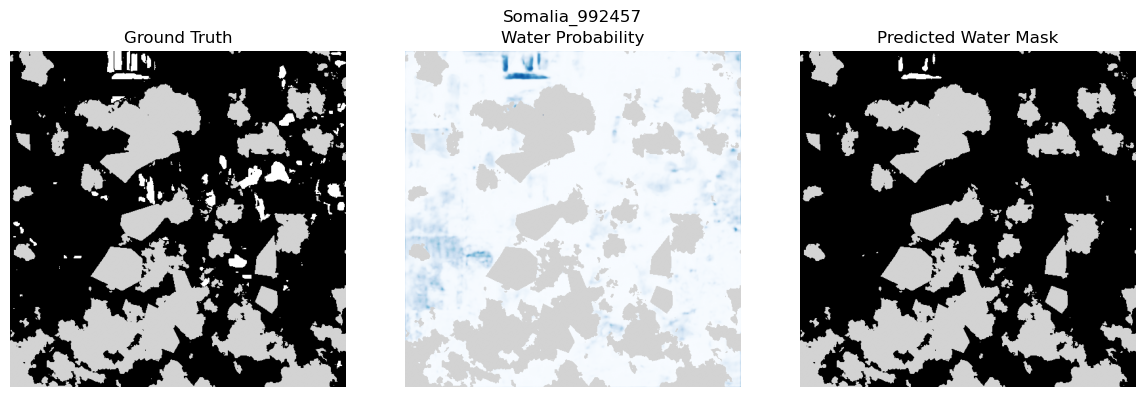

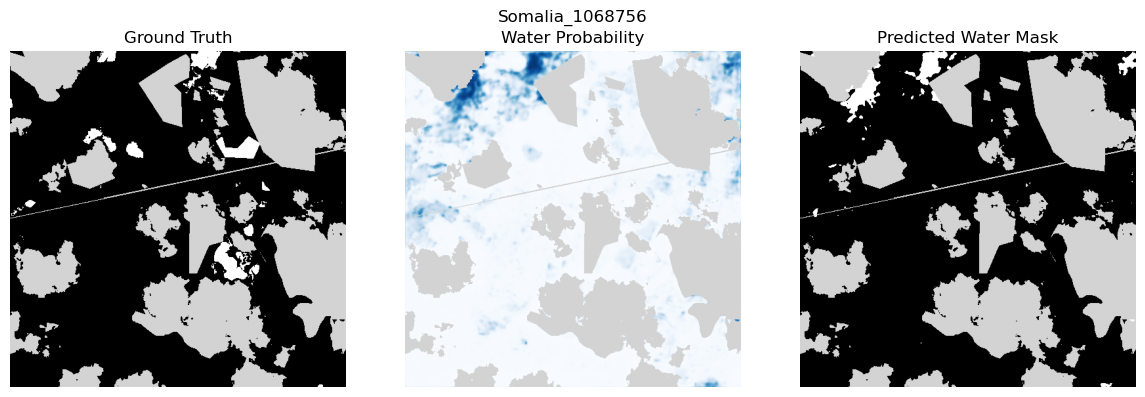

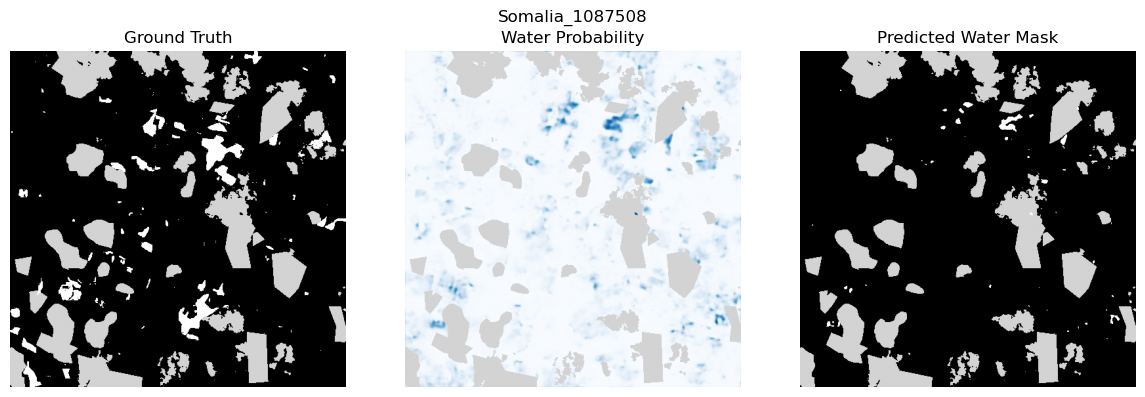

In [10]:
model.eval()

gray_cmap = plt.get_cmap("gray").copy()
gray_cmap.set_bad("lightgray")

blue_cmap = plt.get_cmap("Blues").copy()
blue_cmap.set_bad("lightgray")

for image_id in test_image_ids:

    vv, vh, label = load_image(image_id)
    test_image, test_target, test_valid = prepare_image(vv, vh, label)

    test_tensor = torch.from_numpy(test_image).unsqueeze(0)

    with torch.no_grad():
        prediction = model(test_tensor)

    prob_map = torch.sigmoid(prediction)[0, 0].numpy()
    pred_mask = (prob_map >= 0.5).astype(numpy.uint8)

    ground_truth_display = numpy.where(test_valid, test_target, numpy.nan)
    probability_display = numpy.where(test_valid, prob_map, numpy.nan)
    prediction_display = numpy.where(test_valid, pred_mask, numpy.nan)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(ground_truth_display, cmap=gray_cmap, vmin=0, vmax=1)
    axes[0].set_title("Ground Truth")

    axes[1].imshow(probability_display, cmap=blue_cmap, vmin=0, vmax=1)
    axes[1].set_title("Water Probability")

    axes[2].imshow(prediction_display, cmap=gray_cmap, vmin=0, vmax=1)
    axes[2].set_title("Predicted Water Mask")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(image_id)
    plt.tight_layout()
    plt.show()